# Practice session 01
## Object detection audit

You receive raw predictions from an object detection model and the ground truth boxes for the same images. Your job is to audit the model with pandas and NumPy, then train a tiny model that predicts whether a detection is correct.

**Format:** 10 exercises, **30 minutes**, same style as the Grid Dynamics live coding task.

**Rules**
- Start a timer before running the first cell. Write the start and end time below.
- No AI tools. pandas / NumPy / sklearn docs are allowed, as in a real interview where you would ask the interviewer.
- Write your code in the empty cell under each exercise.
- Use exactly the variable and column names given in the task; your notebook is reviewed afterwards.
- Plots are reviewed for title, axis labels and readability.
- If you get stuck for more than 4 minutes, write a comment explaining your plan and move on. Talking through your plan is part of what the interviewer scores.

**Start time:** ____ &nbsp;&nbsp; **End time:** ____ &nbsp;&nbsp; **Exercises finished:** __ / 10

In [40]:
# Imports you may find useful (run this cell first)
import json
import re
from io import StringIO
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
%matplotlib inline

## Data

`predictions` holds one dict per detected box. `ground_truth` holds the true boxes (at most one box per class per image). Coordinates are in pixels.

In [22]:
predictions = [
    {'image_id': 'img_01.jpg', 'class': 'cat', 'confidence': 0.84, 'x_min': 126, 'y_min': 60, 'x_max': 360, 'y_max': 189},
    {'image_id': 'img_01.jpg', 'class': 'car', 'confidence': 0.87, 'x_min': 180, 'y_min': 163, 'x_max': 371, 'y_max': 274},
    {'image_id': 'img_01.jpg', 'class': 'person', 'confidence': 0.58, 'x_min': 147, 'y_min': 137, 'x_max': 266, 'y_max': 232},
    {'image_id': 'img_02.jpg', 'class': 'dog', 'confidence': 0.56, 'x_min': 59, 'y_min': 85, 'x_max': 242, 'y_max': 214},
    {'image_id': 'img_02.jpg', 'class': 'cat', 'confidence': 0.77, 'x_min': 194, 'y_min': 264, 'x_max': 385, 'y_max': 442},
    {'image_id': 'img_02.jpg', 'class': 'car', 'confidence': 0.35, 'x_min': 240, 'y_min': 91, 'x_max': 316, 'y_max': 204},
    {'image_id': 'img_03.jpg', 'class': 'cat', 'confidence': 0.98, 'x_min': 78, 'y_min': 79, 'x_max': 161, 'y_max': 233},
    {'image_id': 'img_03.jpg', 'class': 'dog', 'confidence': 0.83, 'x_min': 41, 'y_min': 140, 'x_max': 198, 'y_max': 267},
    {'image_id': 'img_03.jpg', 'class': 'car', 'confidence': 0.33, 'x_min': 53, 'y_min': 141, 'x_max': 105, 'y_max': 185},
    {'image_id': 'img_04.jpg', 'class': 'cat', 'confidence': 0.65, 'x_min': 245, 'y_min': 31, 'x_max': 499, 'y_max': 148},
    {'image_id': 'img_04.jpg', 'class': 'car', 'confidence': 0.66, 'x_min': 3, 'y_min': -152, 'x_max': 281, 'y_max': -48},
    {'image_id': 'img_04.jpg', 'class': 'dog', 'confidence': 0.35, 'x_min': 204, 'y_min': 111, 'x_max': 379, 'y_max': 237},
    {'image_id': 'img_05.jpg', 'class': 'car', 'confidence': 0.92, 'x_min': 189, 'y_min': 66, 'x_max': 261, 'y_max': 195},
    {'image_id': 'img_05.jpg', 'class': 'dog', 'confidence': 0.95, 'x_min': 224, 'y_min': 122, 'x_max': 344, 'y_max': 242},
    {'image_id': 'img_05.jpg', 'class': 'cat', 'confidence': 0.63, 'x_min': 34, 'y_min': 89, 'x_max': 80, 'y_max': 153},
    {'image_id': 'img_06.jpg', 'class': 'person', 'confidence': 0.81, 'x_min': 130, 'y_min': 55, 'x_max': 205, 'y_max': 279},
    {'image_id': 'img_06.jpg', 'class': 'dog', 'confidence': 0.85, 'x_min': 112, 'y_min': 33, 'x_max': 309, 'y_max': 197},
    {'image_id': 'img_06.jpg', 'class': 'cat', 'confidence': 0.68, 'x_min': 241, 'y_min': 86, 'x_max': 429, 'y_max': 175},
    {'image_id': 'img_07.jpg', 'class': 'dog', 'confidence': 0.99, 'x_min': 118, 'y_min': 181, 'x_max': 384, 'y_max': 396},
    {'image_id': 'img_07.jpg', 'class': 'cat', 'confidence': 0.87, 'x_min': 216, 'y_min': 97, 'x_max': 359, 'y_max': 175},
    {'image_id': 'img_07.jpg', 'class': 'car', 'confidence': 0.36, 'x_min': 157, 'y_min': 140, 'x_max': 341, 'y_max': 303},
    {'image_id': 'img_08.jpg', 'class': 'person', 'confidence': 0.86, 'x_min': 202, 'y_min': 39, 'x_max': 400, 'y_max': 165},
    {'image_id': 'img_08.jpg', 'class': 'car', 'confidence': 0.89, 'x_min': 82, 'y_min': 141, 'x_max': 299, 'y_max': 230},
    {'image_id': 'img_08.jpg', 'class': 'dog', 'confidence': 0.42, 'x_min': 22, 'y_min': 60, 'x_max': 121, 'y_max': 168},
]

ground_truth = [
    {'image_id': 'img_01.jpg', 'class': 'cat', 'x_min': 120, 'y_min': 44, 'x_max': 336, 'y_max': 167},
    {'image_id': 'img_01.jpg', 'class': 'car', 'x_min': 185, 'y_min': 166, 'x_max': 406, 'y_max': 277},
    {'image_id': 'img_02.jpg', 'class': 'dog', 'x_min': 35, 'y_min': 26, 'x_max': 145, 'y_max': 125},
    {'image_id': 'img_02.jpg', 'class': 'cat', 'x_min': 255, 'y_min': 174, 'x_max': 428, 'y_max': 327},
    {'image_id': 'img_03.jpg', 'class': 'cat', 'x_min': 84, 'y_min': 70, 'x_max': 162, 'y_max': 208},
    {'image_id': 'img_03.jpg', 'class': 'dog', 'x_min': 45, 'y_min': 151, 'x_max': 196, 'y_max': 275},
    {'image_id': 'img_04.jpg', 'class': 'cat', 'x_min': 272, 'y_min': 50, 'x_max': 488, 'y_max': 124},
    {'image_id': 'img_04.jpg', 'class': 'car', 'x_min': 205, 'y_min': 70, 'x_max': 414, 'y_max': 274},
    {'image_id': 'img_05.jpg', 'class': 'car', 'x_min': 189, 'y_min': 72, 'x_max': 270, 'y_max': 196},
    {'image_id': 'img_05.jpg', 'class': 'dog', 'x_min': 226, 'y_min': 111, 'x_max': 359, 'y_max': 243},
    {'image_id': 'img_06.jpg', 'class': 'person', 'x_min': 132, 'y_min': 30, 'x_max': 209, 'y_max': 227},
    {'image_id': 'img_06.jpg', 'class': 'dog', 'x_min': 137, 'y_min': 33, 'x_max': 327, 'y_max': 190},
    {'image_id': 'img_07.jpg', 'class': 'dog', 'x_min': 126, 'y_min': 187, 'x_max': 385, 'y_max': 388},
    {'image_id': 'img_07.jpg', 'class': 'cat', 'x_min': 199, 'y_min': 105, 'x_max': 354, 'y_max': 178},
    {'image_id': 'img_08.jpg', 'class': 'person', 'x_min': 230, 'y_min': 49, 'x_max': 450, 'y_max': 201},
    {'image_id': 'img_08.jpg', 'class': 'car', 'x_min': 75, 'y_min': 137, 'x_max': 302, 'y_max': 221},
]

### Exercise 1: Load the data

Convert `predictions` into a DataFrame called `df` and `ground_truth` into a DataFrame called `gt_df`. Display the first 5 rows of `df` and print its dtypes.

In [23]:
# your code here
df = pd.DataFrame(predictions)
gt_df = pd.DataFrame(ground_truth)

df.head()

,image_id,class,confidence,x_min,y_min,x_max,y_max
0,img_01.jpg,cat,0.84,126,60,360,189
1,img_01.jpg,car,0.87,180,163,371,274
2,img_01.jpg,person,0.58,147,137,266,232
3,img_02.jpg,dog,0.56,59,85,242,214
4,img_02.jpg,cat,0.77,194,264,385,442


In [24]:
df.dtypes

image_id       object
class          object
confidence    float64
x_min           int64
y_min           int64
x_max           int64
y_max           int64
dtype: object

### Exercise 2: Box geometry

Add three columns to `df`: `width` (`x_max - x_min`), `height` (`y_max - y_min`) and `area` (`width * height`).

In [25]:
# your code here
df['width'] = df['x_max'] - df['x_min']
df['height'] = df['y_max'] - df['y_min']
df['area'] = df['width'] * df['height']

df.head()

,image_id,class,confidence,x_min,y_min,x_max,y_max,width,height,area
0,img_01.jpg,cat,0.84,126,60,360,189,234,129,30186
1,img_01.jpg,car,0.87,180,163,371,274,191,111,21201
2,img_01.jpg,person,0.58,147,137,266,232,119,95,11305
3,img_02.jpg,dog,0.56,59,85,242,214,183,129,23607
4,img_02.jpg,cat,0.77,194,264,385,442,191,178,33998


### Exercise 3: High-confidence detections

Create `high_conf_df` with only the rows where `confidence >= 0.80`, sorted by `confidence` descending (ties: `image_id` ascending), with a fresh `0..n-1` index.

In [26]:
# your code here
high_conf_df = df[df['confidence'] >= 0.8].sort_values(by='image_id', ascending=True).sort_values(by='confidence', ascending=False).reset_index(drop=True)
high_conf_df.head()

,image_id,class,confidence,x_min,y_min,x_max,y_max,width,height,area
0,img_07.jpg,dog,0.99,118,181,384,396,266,215,57190
1,img_03.jpg,cat,0.98,78,79,161,233,83,154,12782
2,img_05.jpg,dog,0.95,224,122,344,242,120,120,14400
3,img_05.jpg,car,0.92,189,66,261,195,72,129,9288
4,img_08.jpg,car,0.89,82,141,299,230,217,89,19313


### Exercise 4: Per-class summary

Build `class_summary`, indexed by `class`, with columns `n` (number of detections), `mean_conf` (mean confidence) and `max_area` (largest area). Sort by `n` descending, then by class name ascending.

In [27]:
# your code here
class_summary = df.groupby('class').agg(
    count=('class', 'count'),
    avg_confidence=('confidence', 'mean'),
    avg_area=('area', 'mean')
).reset_index()

class_summary

,class,count,avg_confidence,avg_area
0,car,7,0.625714,17083.142857
1,cat,7,0.774286,19644.857143
2,dog,7,0.707143,25740.857143
3,person,3,0.750000,17684.333333


### Exercise 5: Best detection per image

Create `top_per_image`: for each `image_id`, keep only the row with the highest confidence. One row per image, sorted by `image_id`, fresh index.

In [28]:
# your code here
top_per_image = df.loc[df.groupby('image_id')['confidence'].idxmax()].reset_index(drop=True)
top_per_image

,image_id,class,confidence,x_min,y_min,x_max,y_max,width,height,area
0,img_01.jpg,car,0.87,180,163,371,274,191,111,21201
1,img_02.jpg,cat,0.77,194,264,385,442,191,178,33998
2,img_03.jpg,cat,0.98,78,79,161,233,83,154,12782
3,img_04.jpg,car,0.66,3,-152,281,-48,278,104,28912
4,img_05.jpg,dog,0.95,224,122,344,242,120,120,14400
5,img_06.jpg,dog,0.85,112,33,309,197,197,164,32308
6,img_07.jpg,dog,0.99,118,181,384,396,266,215,57190
7,img_08.jpg,car,0.89,82,141,299,230,217,89,19313


### Exercise 6: Box shape with NumPy

Without loops, add `aspect = width / height` and a column `shape` using `np.select`: `'wide'` if aspect > 1.2, `'tall'` if aspect < 0.8, otherwise `'square'`. Then create `shape_counts = df['shape'].value_counts().sort_index()`.

In [29]:
# your code here
df['aspect'] = df['width'] / df['height']

conditions = [df['aspect'] > 1.2, df['aspect'] < 0.8]
choices = ['wide', 'tall']
df['category'] = np.select(conditions, choices, default='square')

category_counts = df['category'].value_counts().sort_index()
category_counts

category
square     5
tall       5
wide      14
Name: count, dtype: int64

### Exercise 7: IoU against ground truth

Left-merge `gt_df` onto `df` on `image_id` and `class` (suffixes `('', '_gt')`), keeping the original row order. Compute the Intersection over Union with vectorised NumPy:

$$\text{IoU} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|}$$

where the intersection width is $\max(0, \min(x_{max}^A, x_{max}^B) - \max(x_{min}^A, x_{min}^B))$ (same for height). Store it in `df['iou']`, with `0` for predictions that have no matching ground truth box. Finally add `is_correct = (iou >= 0.5).astype(int)`. Keep the result in `df` (drop the `_gt` columns or keep them, your choice).

In [34]:
# your code here
df = df.merge(gt_df, on=['image_id', 'class'], how='left', suffixes=('', '_gt'))

inter_w = np.maximum(0, np.minimum(df['x_max'], df['x_max_gt']) - np.maximum(df['x_min'], df['x_min_gt']))
inter_h = np.maximum(0, np.minimum(df['y_max'], df['y_max_gt']) - np.maximum(df['y_min'], df['y_min_gt']))
intersection = inter_w * inter_h

area_gt = (df['x_max_gt'] - df['x_min_gt']) * (df['y_max_gt'] - df['y_min_gt'])
union = df['area'] + area_gt - intersection

df['iou'] = np.where(df['x_min_gt'].isna(), 0, intersection / union)
df['is_correct'] = (df['iou'] >= 0.5).astype(int)

new_df = pd.merge(df, gt_df, on=['image_id', 'class'], suffixes=('', '_gt'))

new_df

,image_id,class,confidence,x_min,y_min,x_max,y_max,width,height,area,aspect,category,x_min_gt,y_min_gt,x_max_gt,y_max_gt,iou,is_correct,x_min_gt,y_min_gt,x_max_gt,y_max_gt
0,img_01.jpg,cat,0.84,126,60,360,189,234,129,30186,1.813953,wide,120.0,44.0,336.0,167.0,0.655408,1,120,44,336,167
1,img_01.jpg,car,0.87,180,163,371,274,191,111,21201,1.720721,wide,185.0,166.0,406.0,277.0,0.783341,1,185,166,406,277
2,img_02.jpg,dog,0.56,59,85,242,214,183,129,23607,1.418605,wide,35.0,26.0,145.0,125.0,0.110764,0,35,26,145,125
3,img_02.jpg,cat,0.77,194,264,385,442,191,178,33998,1.073034,square,255.0,174.0,428.0,327.0,0.156665,0,255,174,428,327
4,img_03.jpg,cat,0.98,78,79,161,233,83,154,12782,0.538961,tall,84.0,70.0,162.0,208.0,0.729670,1,84,70,162,208
5,img_03.jpg,dog,0.83,41,140,198,267,157,127,19939,1.236220,wide,45.0,151.0,196.0,275.0,0.828297,1,45,151,196,275
6,img_04.jpg,cat,0.65,245,31,499,148,254,117,29718,2.170940,wide,272.0,50.0,488.0,124.0,0.537856,1,272,50,488,124
7,img_04.jpg,car,0.66,3,-152,281,-48,278,104,28912,2.673077,wide,205.0,70.0,414.0,274.0,0.000000,0,205,70,414,274
8,img_05.jpg,car,0.92,189,66,261,195,72,129,9288,0.558140,tall,189.0,72.0,270.0,196.0,0.845361,1,189,72,270,196
9,img_05.jpg,dog,0.95,224,122,344,242,120,120,14400,1.000000,square,226.0,111.0,359.0,243.0,0.795684,1,226,111,359,243


### Exercise 8: Plot

Make one figure with two side-by-side subplots: (1) a boxplot of `confidence` for correct vs incorrect detections, (2) a scatter of `area` vs `iou` coloured by `class`. Add titles and axis labels. In a short comment, say whether confidence looks useful for separating correct from incorrect boxes.

Text(0.5, 1.0, 'Scatter plot of IoU vs area by class')

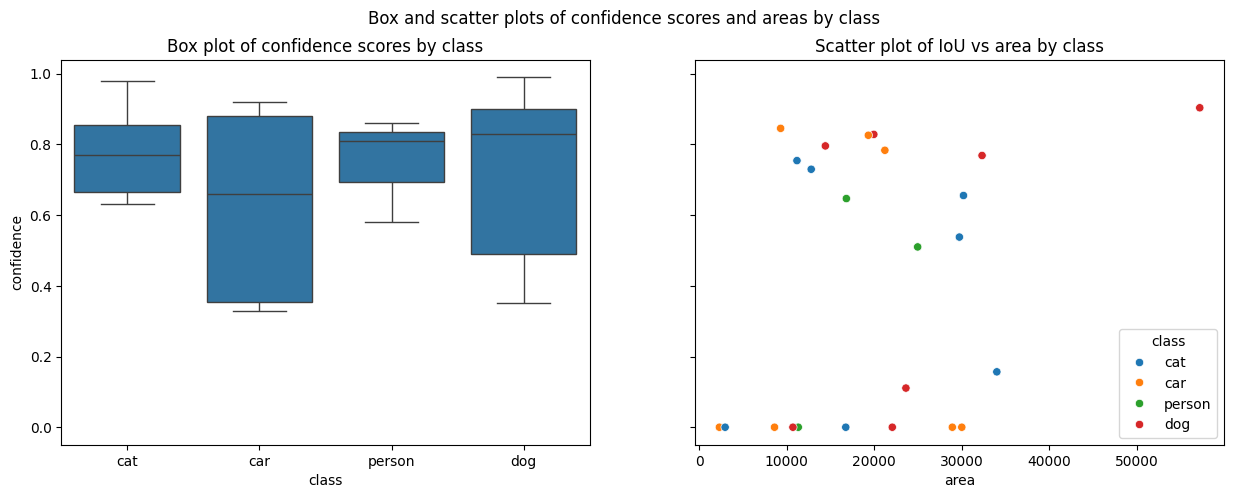

In [35]:
# your code here
# sns.boxplot(x='class', y='confidence', data=df)
# sns.scatterplot(x='area', y='confidence', hue='class', data=df)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
fig.suptitle('Box and scatter plots of confidence scores and areas by class')

sns.boxplot(ax=axes[0], x='class', y='confidence', data=df)
axes[0].set_title('Box plot of confidence scores by class')

sns.scatterplot(ax=axes[1], x='area', y='iou', data=df, hue='class')
axes[1].set_title('Scatter plot of IoU vs area by class')

### Exercise 9: Train/test split

Use features `X = df[['confidence', 'area', 'aspect']]` and target `y = df['is_correct']`. Split with `train_test_split(test_size=0.25, random_state=42, stratify=y)` into `X_train, X_test, y_train, y_test`. Print the class balance of `y_train` and `y_test`.

In [36]:
# your code here
X = df[['confidence', 'area', 'aspect']]
y = df['is_correct']

train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.25, random_state=1111, stratify=y)
print(f"Train set size: {train_X.shape[0]} samples")
print(f"Test set size: {test_X.shape[0]} samples")

Train set size: 18 samples
Test set size: 6 samples


### Exercise 10: Logistic regression

Fit `model = LogisticRegression(max_iter=1000)` on the training set. Store the test accuracy in `acc` and print the confusion matrix. In a comment: why is accuracy alone risky on a dataset this small?

In [41]:
# your code here
lr = LogisticRegression(random_state=1111)
model = lr.fit(train_X, train_y)
y_pred = model.predict(test_X)

conf_matrix = confusion_matrix(test_y, y_pred)
conf_matrix_df = pd.DataFrame(conf_matrix, index=['Actual Negative', 'Actual Positive'], columns=['Predicted Negative', 'Predicted Positive'])
conf_matrix_df

,Predicted Negative,Predicted Positive
Actual Negative,1,2
Actual Positive,1,2


In [42]:
acc = accuracy_score(test_y, y_pred)
prec = precision_score(test_y, y_pred)
rec = recall_score(test_y, y_pred)
f1 = f1_score(test_y, y_pred)

scores = {
    'accuracy': acc,
    'precision': prec,
    'recall': rec,
    'f1_score': f1}

scores_df = pd.DataFrame([scores])
scores_df

,accuracy,precision,recall,f1_score
0,0.5,0.5,0.666667,0.571429


Accuracy is a weak measure because it takes positive predictions to all predictions, while precision takes true positive and true negative sum to all predictions, so it is better to check for precision.

## Interviewer follow-up questions

Answer in 2 to 4 sentences each, as you would say it out loud.

1. `area` is in the hundreds of thousands while `confidence` is between 0 and 1. What does that do to logistic regression and how would you fix it?
2. Why did you use `stratify=y`, and what could happen without it on 24 rows?
3. IoU >= 0.5 is a threshold. How would you choose the confidence threshold for production if false positives are expensive?

**My answers:**

1. scale the 'area' feature so it has variance 1 and mean 0
2. it preserves the same percentage of target class in train and test set, if we don't have it on such small set random split might put 0 positive cases in test set
3. i dont understand the question